# LangGraph Agentic AI

1. Nodes - Python Function
2. Edges - Condition/Logic/Reasoning/Connector
3. State - Data Structure that evolves over times/DataBase Repository/Environment
4. Graph - Workflow/Flow-Chart

In [1]:
from typing import TypedDict
class SomeState(TypedDict):
    att1: str
    att2: str

In [3]:
def some_function(state: SomeState):
    state['att1'] = "Value Changed by node some_function()"
    return state

In [ ]:
#!pip install -U langgraph

In [5]:
from langgraph.graph import StateGraph

In [7]:
graph = StateGraph(SomeState)

In [9]:
graph.add_node('node1', some_function)

In [11]:
from langgraph.graph.state import END

In [13]:
graph.add_edge("node1", END)

In [15]:
graph.set_entry_point('node1')

In [17]:
compiled_graph = graph.compile()

In [19]:
from IPython.display import Image

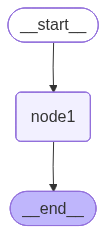

In [21]:
Image(compiled_graph.get_graph().draw_mermaid_png())

In [23]:
from typing import TypedDict

In [25]:
class State(TypedDict):
    graph_state: str

In [27]:
def first_node(state):
    print("This is my first node")
    return {"graph_state": state['graph_state'] + "Hi, I am traveling "}

def second_node(state):
    print("This is my second node")
    return {"graph_state": state['graph_state'] + "United Kigdom - London"}

def third_node(state):
    print("This is my third node")
    return {"graph_state": state['graph_state'] + "United State of America (USA)"}    

In [29]:
# Logic
import random
from typing import Literal

def decide_location(state) -> Literal["second_node", "third_node"]:
    graph_state = state['graph_state']
    if random.random() < 0.5:
        return "second_node"
    else:
        return "third_node"        

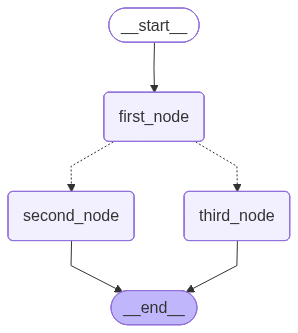

In [31]:
# Building LangGraph Model (connect with node, edge and end)

from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

builder = StateGraph(State)
builder.add_node("first_node", first_node)
builder.add_node("second_node", second_node)
builder.add_node("third_node", third_node)

builder.add_edge(START, 'first_node')
builder.add_conditional_edges("first_node", decide_location)
builder.add_edge("second_node", END)
builder.add_edge("third_node", END)

graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [33]:
graph.invoke({"graph_state": "Hi, my name is Kumar Sundram, "})

This is my first node
This is my second node


{'graph_state': 'Hi, my name is Kumar Sundram, Hi, I am traveling United Kigdom - London'}

In [35]:
graph.invoke({"graph_state": "Hi, my name is Kumar Sundram, "})

This is my first node
This is my second node


{'graph_state': 'Hi, my name is Kumar Sundram, Hi, I am traveling United Kigdom - London'}

In [37]:
graph.invoke({"graph_state": "Hi, my name is Kumar Sundram, "})

This is my first node
This is my third node


{'graph_state': 'Hi, my name is Kumar Sundram, Hi, I am traveling United State of America (USA)'}